# Nimega kõnelejate teemade jaotus

See notebook arvutab ainult nende diariseeritud kõnelejate kohta, kellele nimevastete tabelis on leitud nimi. Iga nime ja teema lõikes näidatakse teemalõikude arvu, arutelude arvu ning kõneleja teemaga seotud kõneaega. Teema kestus summeerib kõneleja kõneaja teemalõikudes, mitte kogu arutelu seinakella aega.

Nimevasteid võetakse failist `data/diarization/speaker-name-detections-2026.csv`; kasutatakse High ja Medium kindlusega vasteid. Dubleerivad SoundCloudi üleslaadimised loetakse üheks kanooniliseks aruteluks.

In [1]:
import bisect
import json
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

from arvamusfestivali_transcripts.diarization_analysis import align_topic_chunks_to_speakers
from arvamusfestivali_transcripts.text_quality import has_meaningful_text

project_root = Path.cwd().resolve()
if not (project_root / "data/diarization/2026").exists():
    project_root = project_root.parent
result_root = project_root / "data/topic-analysis/results"
diarization_dir = project_root / "data/diarization/2026"
name_file = project_root / "data/diarization/speaker-name-detections-2026.csv"

for required in [
    result_root / "jev-semantic-all/assignments.parquet",
    result_root / "segment-dataset/all-segments.parquet",
    result_root / "talk-metadata/talks.parquet",
    diarization_dir,
    name_file,
]:
    if not required.exists():
        raise FileNotFoundError(required)

MIN_NAME_CONFIDENCE = {"High", "Medium"}
TOPICS_TO_SHOW_PER_SPEAKER = 12


## Valmista kanoonilised arutelud ja teemalõigud

Kanoonilise vestluse ID ühendab duplikaatüleslaadimised. Iga teemalõik joondatakse vastava salvestise kõnelejapööretega aja kattuvuse alusel.

In [2]:
talks = pd.read_parquet(
    result_root / "talk-metadata/talks.parquet",
    columns=["episode_id", "duplicate_episode_ids", "title"],
)
talks["episode_id"] = talks.episode_id.astype(str)
alias_rows = [
    {"episode_id": str(alias), "canonical_episode_id": str(row.episode_id), "title": row.title}
    for row in talks.itertuples()
    for alias in json.loads(row.duplicate_episode_ids)
]
episode_aliases = pd.DataFrame(alias_rows).drop_duplicates("episode_id")
available_ids = {path.stem for path in diarization_dir.glob("*.json")}
available_aliases = episode_aliases.loc[episode_aliases.episode_id.isin(available_ids)].copy()

canonical_files = {}
selected_file_ids = {}
for canonical_id, group in available_aliases.groupby("canonical_episode_id"):
    aliases = sorted(group.episode_id)
    selected_id = canonical_id if canonical_id in aliases else aliases[0]
    canonical_files[canonical_id] = diarization_dir / f"{selected_id}.json"
    selected_file_ids[canonical_id] = selected_id

assignments = pd.read_parquet(
    result_root / "jev-semantic-all/assignments.parquet",
    columns=[
        "segment_key", "jev_topic_id", "jev_topic_name",
        "jev_high_level_id", "jev_high_level_name",
    ],
)
segment_timing = pd.read_parquet(
    result_root / "segment-dataset/all-segments.parquet",
    columns=["segment_key", "episode_id", "start_seconds", "end_seconds", "text"],
)
meaningful = segment_timing.text.map(has_meaningful_text)
segment_timing = segment_timing.loc[meaningful].copy()
assignments = assignments.loc[assignments.segment_key.isin(segment_timing.segment_key)].copy()
topic_chunks = assignments.merge(segment_timing, on="segment_key", how="inner", validate="one_to_one")
topic_chunks["episode_id"] = topic_chunks.episode_id.astype(str)

print(f"Kanoonilisi arutelusid: {len(canonical_files):,}")
print(f"Teemalõike: {len(topic_chunks):,}")


Kanoonilisi arutelusid: 219
Teemalõike: 4,139


## Lae nimed ja arvuta kõneleja-teema kattuvus

Nimevaste on seotud konkreetse diariseerimisfaili ja selle `SPEAKER_XX` sildiga. Mitmetähenduslikud või nime puudumisega read jäetakse nimede loendist välja.

In [3]:
name_rows = pd.read_csv(name_file).fillna("")
name_rows = name_rows.loc[
    name_rows.confidence.isin(MIN_NAME_CONFIDENCE)
    & name_rows.speaker_label.ne("")
    & name_rows.suggested_name.ne("")
].copy()
name_rows["episode_id"] = name_rows.episode_id.astype(str)
name_rows["speaker_label"] = name_rows.speaker_label.astype(str)

# Keep only unambiguous episode/speaker-to-name mappings.
name_counts = name_rows.groupby(["episode_id", "speaker_label"]).suggested_name.nunique()
valid_name_keys = name_counts[name_counts.eq(1)].reset_index()[["episode_id", "speaker_label"]]
name_rows = name_rows.merge(
    valid_name_keys, on=["episode_id", "speaker_label"], how="inner", validate="many_to_one"
).drop_duplicates(["episode_id", "speaker_label"])
names_by_file = name_rows.set_index(["episode_id", "speaker_label"]).suggested_name.to_dict()

alignment_rows = []
for canonical_id, path in sorted(canonical_files.items()):
    payload = json.loads(path.read_text(encoding="utf-8"))
    chunks = (
        topic_chunks.loc[topic_chunks.episode_id.eq(canonical_id)]
        .rename(columns={
            "jev_topic_id": "detailed_topic_id",
            "jev_topic_name": "detailed_topic_name",
            "jev_high_level_id": "high_level_id",
            "jev_high_level_name": "high_level_name",
        })[[
            "start_seconds", "end_seconds", "segment_key",
            "detailed_topic_id", "detailed_topic_name",
            "high_level_id", "high_level_name",
        ]]
        .to_dict("records")
    )
    turns = sorted(payload.get("turns", []), key=lambda turn: float(turn["start_seconds"]))
    turn_starts = [float(turn["start_seconds"]) for turn in turns]
    prefix_max_ends = []
    max_end = float("-inf")
    for turn in turns:
        max_end = max(max_end, float(turn["end_seconds"]))
        prefix_max_ends.append(max_end)
    aligned = []
    for chunk in chunks:
        chunk_start = float(chunk["start_seconds"])
        chunk_end = float(chunk["end_seconds"])
        stop = bisect.bisect_left(turn_starts, chunk_end)
        first = bisect.bisect_right(prefix_max_ends, chunk_start, 0, stop)
        metadata = {key: value for key, value in chunk.items() if key not in {"start_seconds", "end_seconds"}}
        for turn in turns[first:stop]:
            overlap = min(chunk_end, float(turn["end_seconds"])) - max(chunk_start, float(turn["start_seconds"]))
            if overlap > 0:
                aligned.append({**metadata, "speaker": str(turn["speaker"]), "overlap_seconds": overlap})
    selected_file_id = selected_file_ids[canonical_id]
    for row in aligned:
        name = names_by_file.get((selected_file_id, row["speaker"]))
        if name:
            row.update({
                "speaker_name": name,
                "canonical_episode_id": canonical_id,
                "title": available_aliases.loc[
                    available_aliases.canonical_episode_id.eq(canonical_id), "title"
                ].iloc[0],
            })
            alignment_rows.append(row)

alignment = pd.DataFrame(alignment_rows)
if alignment.empty:
    raise ValueError("Ühtegi nimega kõneleja-teema kattuvust ei leitud.")
print(f"Nimega kõnelejaid: {alignment.speaker_name.nunique():,}")
print(f"Nimega kõneleja-teema kattuvusi: {len(alignment):,}")
display(alignment.head())


Nimega kõnelejaid: 302
Nimega kõneleja-teema kattuvusi: 36,840


segment_key,detailed_topic_id,detailed_topic_name,high_level_id,high_level_name,speaker,overlap_seconds,speaker_name,canonical_episode_id,title
semantic:bge:leaf-local-6-2:42:2247188684:000000011000-000000312960,1,Tööõnnetuste ennetus ja tööohutuse teadlikkus,work,"Tööelu, juhtimine ja töötajate õigused",SPEAKER_04,5.079,Mirko Ojakivi,2247188684,Kas kiirustades elad kauem?
semantic:bge:leaf-local-6-2:42:2247188684:000000011000-000000312960,1,Tööõnnetuste ennetus ja tööohutuse teadlikkus,work,"Tööelu, juhtimine ja töötajate õigused",SPEAKER_04,14.715,Mirko Ojakivi,2247188684,Kas kiirustades elad kauem?
semantic:bge:leaf-local-6-2:42:2247188684:000000011000-000000312960,1,Tööõnnetuste ennetus ja tööohutuse teadlikkus,work,"Tööelu, juhtimine ja töötajate õigused",SPEAKER_04,2.531,Mirko Ojakivi,2247188684,Kas kiirustades elad kauem?
semantic:bge:leaf-local-6-2:42:2247188684:000000011000-000000312960,1,Tööõnnetuste ennetus ja tööohutuse teadlikkus,work,"Tööelu, juhtimine ja töötajate õigused",SPEAKER_04,15.913,Mirko Ojakivi,2247188684,Kas kiirustades elad kauem?
semantic:bge:leaf-local-6-2:42:2247188684:000000011000-000000312960,1,Tööõnnetuste ennetus ja tööohutuse teadlikkus,work,"Tööelu, juhtimine ja töötajate õigused",SPEAKER_04,1.080,Mirko Ojakivi,2247188684,Kas kiirustades elad kauem?


## Teemade jaotus nimega kõnelejate lõikes

`segment_count` loendab unikaalseid semantilisi teemalõike, millega kõneleja kõneaeg kattub. `discussion_count` loendab unikaalseid kanoonilisi arutelusid. `topic_speech_minutes` summeerib kõneleja kõneaja selle teema lõikudes. Kui üks arutelu sisaldab sama teema all mitu teemalõiku, loendatakse need kõik eraldi segmentidena.

In [4]:
def summarize_named_topics(frame, topic_id, topic_name):
    return (
        frame.groupby(["speaker_name", topic_id, topic_name], as_index=False)
        .agg(
            segment_count=("segment_key", "nunique"),
            discussion_count=("canonical_episode_id", "nunique"),
            topic_speech_seconds=("overlap_seconds", "sum"),
        )
        .assign(topic_speech_minutes=lambda data: data.topic_speech_seconds / 60)
        .sort_values(["speaker_name", "topic_speech_seconds"], ascending=[True, False])
        .reset_index(drop=True)
    )

detailed_topic_summary = summarize_named_topics(
    alignment, "detailed_topic_id", "detailed_topic_name"
)
high_level_topic_summary = summarize_named_topics(
    alignment, "high_level_id", "high_level_name"
)

display(detailed_topic_summary)


speaker_name,detailed_topic_id,detailed_topic_name,segment_count,discussion_count,topic_speech_seconds,topic_speech_minutes
Aavo Salustav,31,Valimiste valvamine ja rahastamise läbipaistvus,4,1,68.197,1.136617
Aavo Salustav,-1,Unassigned,1,1,3.103,0.051717
Aavo Salustav,118,Visiooni ja väärtuste vaidlus riigijuhtimises,1,1,2.539,0.042317
Agne Andro,36,Lastekodukasvamise kogemus ja märkamise roll,4,1,354.579,5.909650
Agne Andro,183,noorte vägivalla taga peituv tähelepanuvajadus,6,1,281.379,4.689650
Agne Andro,129,lapsega esmakontakti loomine lastekaitses,1,1,24.102,0.401700
Agne Andro,232,Noorte vanglast saatmine pärast rasket vägivalda,1,1,23.660,0.394333
Airi Mittendorf,16,Töökiusamise piiri tõmbamine tööl,11,1,672.044,11.200733
Airi Mittendorf,18,Töökiusu ja vaidluste piiritlemine töösuhtes,2,1,75.836,1.263933
Airi Mittendorf,-1,Unassigned,2,1,6.261,0.104350


## Kõneleja kaupa kiire võrdlus

Allolev joonis näitab iga nimega kõneleja kõige pikema kõneajaga teemasid. Tabelid jäävad täielikuks ka siis, kui teemad joonisel kärbitakse.

Valitud kõneleja: Inger Klesment
Kõrgetasemeliste teemade kokkuvõte


speaker_name,detailed_topic_id,detailed_topic_name,segment_count,discussion_count,topic_speech_seconds,topic_speech_minutes
Inger Klesment,171,Tehisintellekti kasutus kooliõppes,1,1,65.154,1.085900
Inger Klesment,145,Õpetajate ja õpilaste AI-kohandumine,1,1,91.454,1.524233
Inger Klesment,60,andmejärelevalve ja tehisintellekti piirid,2,1,205.296,3.421600
Inger Klesment,11,laste nutiekraani ja sotsiaalmeedia sõltuvus,2,1,284.545,4.742417
Inger Klesment,209,Laste internetikäitumine ja abiotsimine,5,1,797.911,13.298517
Inger Klesment,76,Laste ja AI-petuste internetiohud,10,2,1387.898,23.131633
Inger Klesment,95,Veebis lastega suhtlemise seksuaalriskid,16,2,1515.201,25.253350


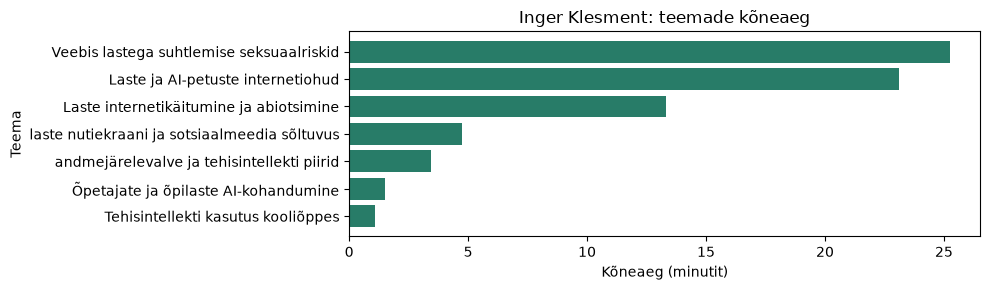

speaker_name,high_level_id,high_level_name,segment_count,discussion_count,topic_speech_seconds,topic_speech_minutes
Aavo Salustav,governance,"Riigijuhtimine, kodanikuühiskond ja õigus",5,1,70.736,1.178933
Aavo Salustav,unassigned,Määramata,1,1,3.103,0.051717
Agne Andro,children,Laste ja noorte kaitse ning toetamine,12,1,683.720,11.395333
Airi Mittendorf,work,"Tööelu, juhtimine ja töötajate õigused",13,1,747.880,12.464667
Airi Mittendorf,unassigned,Määramata,2,1,6.261,0.104350
Aivar Loopalu,culture,"Kultuur, loome ja pärand",6,1,488.699,8.144983
Aivar Loopalu,unassigned,Määramata,2,1,86.349,1.439150
Aivar Loopalu,healthcare,"Tervishoid, ravi ja terviseandmed",1,1,55.653,0.927550
Aivar Loopalu,governance,"Riigijuhtimine, kodanikuühiskond ja õigus",1,1,0.827,0.013783
Alar,healthcare,"Tervishoid, ravi ja terviseandmed",11,1,942.736,15.712267


In [5]:
# Select one speaker to inspect. By default, show the speaker with the most aligned speech.
SELECTED_SPEAKER_NAME = None
speaker_totals = alignment.groupby("speaker_name").overlap_seconds.sum().sort_values(ascending=False)
selected_speaker_name = SELECTED_SPEAKER_NAME or speaker_totals.index[0]
selected_topics = detailed_topic_summary.loc[
    detailed_topic_summary.speaker_name.eq(selected_speaker_name)
].nlargest(TOPICS_TO_SHOW_PER_SPEAKER, "topic_speech_minutes").sort_values("topic_speech_minutes")

print(f"Valitud kõneleja: {selected_speaker_name}")
display(selected_topics)
fig, ax = plt.subplots(figsize=(10, max(3, 0.38 * len(selected_topics))))
ax.barh(selected_topics.detailed_topic_name, selected_topics.topic_speech_minutes, color="#287c68")
ax.set(title=f"{selected_speaker_name}: teemade kõneaeg", xlabel="Kõneaeg (minutit)")
ax.set_ylabel("Teema")
fig.tight_layout()
plt.show()

print("Kõrgetasemeliste teemade kokkuvõte")
display(high_level_topic_summary)


## Tõlgendamisel arvesta

- Nimevaste on automaatne soovitus ning võib olla vale; analüüs kasutab nimefaili High ja Medium kindlusega ridu.
- Kõneaeg on diariseerimise ja teemalõigu ajaline kattuvus. See ei tõesta, et kõneleja teema algatas või selle kujundas.
- `segment_count` loendab teema määramise lõike, mitte lauseid ega kõnevoorusid.
- `discussion_count` arvestab duplikaatüleslaadimised üheks kanooniliseks aruteluks.
- Nimeta kõnelejad jäetakse välja.